<a href="https://colab.research.google.com/github/DAustinGit/SolubilityML/blob/main/solubilityML_ensembles.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Further analysis of stacked training models

###load data from database

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split, learning_curve
df = pd.read_csv('https://raw.githubusercontent.com/dataprofessor/data/refs/heads/master/delaney_solubility_with_descriptors.csv')
y = df['logS']   # Y is feature used for training
x = df.drop('logS', axis=1)   #X is the feature we are predicting drop logS and axis = 1 --> work in coluns

x_train, x_test, y_train, y_test = train_test_split (x, y, test_size= 0.2, random_state = 100) #splits the data for train and test sets testing set is 20% of data
print (x_train)

     MolLogP    MolWt  NumRotatableBonds  AromaticProportion
107  3.14280  112.216                5.0            0.000000
378 -2.07850  142.070                0.0            0.000000
529 -0.47730  168.152                0.0            0.000000
546 -0.86740  154.125                0.0            0.000000
320  1.62150  100.161                2.0            0.000000
..       ...      ...                ...                 ...
802  3.00254  250.301                1.0            0.842105
53   2.13860   82.146                3.0            0.000000
350  5.76304  256.348                0.0            0.900000
79   3.89960  186.339               10.0            0.000000
792  2.52334  310.297                3.0            0.300000

[915 rows x 4 columns]


##KNN BR stacking

use ridge regression using RidgeCV - affectively adds some devience into the traing fit to reduce deviance in the rest fit https://www.youtube.com/watch?v=Q81RR3yKn30&t=85s

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn import linear_model
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import StackingRegressor
from sklearn.model_selection import GridSearchCV

base_learners = [
    ('lr', linear_model.BayesianRidge()),
    ('knn', KNeighborsRegressor())
]

stacking_ensemble = StackingRegressor(
    estimators=base_learners,
    final_estimator=RidgeCV(),
    cv = 3

)

pipeline = Pipeline([
  ('scaler', StandardScaler()),
  ('stack', stacking_ensemble)
])

param_grid = {


    # Tune the KNN model hidden inside the stack step
    'stack__knn__n_neighbors': [9, 11, 15, 21],

    # Tune the weights parameter of the KNN model inside the stack step
    'stack__knn__weights': ['uniform']
}
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(x_train, y_train)

# 6. Output the results
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best CV R² Score: {grid_search.best_score_:.4f}")
print(f"Test Set R² Score: {grid_search.score(x_test, y_test):.4f}")


Best Parameters: {'stack__knn__n_neighbors': 9, 'stack__knn__weights': 'uniform'}
Best CV R² Score: 0.8459
Test Set R² Score: 0.8593


###Assesing the model
measure the training score training R2 - test R2

In [ ]:
train_score = grid_search.score(x_train, y_train)

# 2. Calculate the score on the test data
test_score = grid_search.score(x_test, y_test)

print(f"Training R² Score: {train_score:.4f}")
print(f"Test R² Score:     {test_score:.4f}")

# 3. Evaluate the gap
gap = train_score - test_score
print(f"Performance Gap:   {gap:.4f}")


Training R² Score: 0.8826
Test R² Score:     0.8593
Performance Gap:   0.0233


###notes


*   perfomance gap is quite high
*   high test score is good
*   model is overfitting



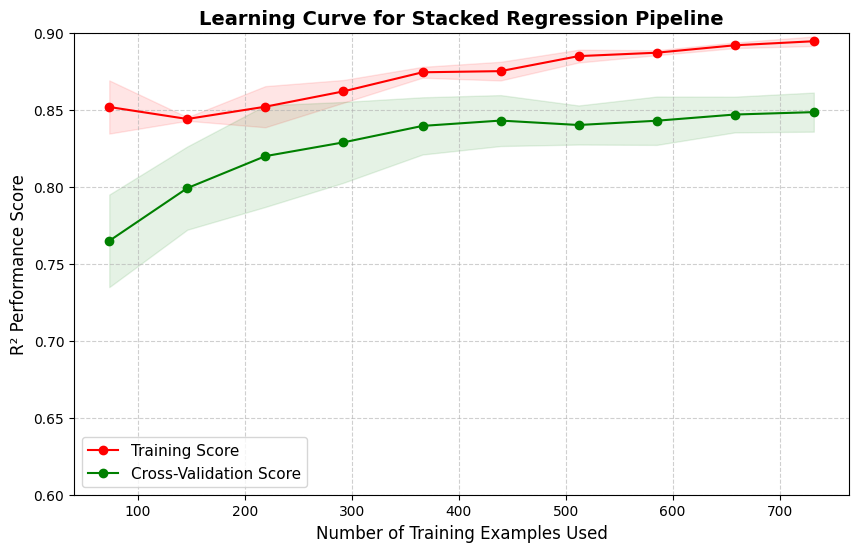

In [ ]:
import numpy as np
import matplotlib.pyplot as plt




# 2. Calculate the learning curve data
# train_sizes dictates the fractions of the training set to use (e.g., 10% up to 100%)
train_sizes, train_scores, validation_scores = learning_curve(
    estimator=pipeline,
    X=x_train,
    y=y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,                  # 5-fold cross-validation at each data size step
    scoring='r2',          # Evaluate using the R² score
    n_jobs=-1
)

# 3. Calculate the mean and standard deviation across the CV folds
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
validation_mean = np.mean(validation_scores, axis=1)
validation_std = np.std(validation_scores, axis=1)

# 4. Generate the plot
plt.figure(figsize=(10, 6))

# Plot training scores
plt.plot(train_sizes, train_mean, 'o-', color="r", label="Training Score")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color="r")

# Plot validation scores
plt.plot(train_sizes, validation_mean, 'o-', color="g", label="Cross-Validation Score")
plt.fill_between(train_sizes, validation_mean - validation_std, validation_mean + validation_std, alpha=0.1, color="g")

# Formatting elements
plt.title("Learning Curve for Stacked Regression Pipeline", fontsize=14, fontweight='bold')

plt.xlabel("Number of Training Examples Used", fontsize=12)
plt.ylabel("R² Performance Score", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc="best", fontsize=11)
plt.ylim(0.6, 0.9) # Caps the Y-axis logically for R² interpretation
plt.show()

## KNN GPR Ensemble

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from sklearn.linear_model import RidgeCV
from sklearn import linear_model
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import StackingRegressor
from sklearn.model_selection import GridSearchCV

#kernel = 1*RBF(length_scale=[1.0,1.0,1.0,1.0], length_scale_bounds=(1e-2, 1e2))

base_learners = [
    ('gpr', GaussianProcessRegressor(optimizer=None, normalize_y=True,  alpha=1e-3)),
    ('br', linear_model.BayesianRidge()),
    ('knn', KNeighborsRegressor())
]

stacking_ensemble = StackingRegressor(
    estimators=base_learners,
    final_estimator=RidgeCV(),
    cv = 3

)

pipeline = Pipeline([
  ('scaler', StandardScaler()),
  ('stack', stacking_ensemble)
])

param_grid = {

    "stack__gpr__kernel": [
        1.0 * RBF(length_scale=[0.5, 0.5, 0.5, 0.5], length_scale_bounds="fixed"),
        1.0 * RBF(length_scale=[1.0, 1.0, 1.0, 1.0], length_scale_bounds="fixed"),
        1.0 * RBF(length_scale=[2.0, 2.0, 2.0, 2.0], length_scale_bounds="fixed"),
        # You can add specific custom weighting if you suspect a feature is highly sensitive:
        1.0 * RBF(length_scale=[0.5, 2.0, 1.0, 1.0], length_scale_bounds="fixed"),
    ],
    # Tune the KNN model hidden inside the stack step
    'stack__gpr__alpha': [1e-4, 1e-2, 1e0],

    # Tune the weights parameter of the KNN model inside the stack step
    'stack__knn__weights': ['uniform'],
    'stack__knn__n_neighbors': [9,11,15,21]


}
grid_gpr = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
)

grid_gpr.fit(x_train, y_train)

try:
    print("Training grid search sequentially... please wait...")
    grid_gpr.fit(x_train, y_train)

    print("\n--- Model Trained Successfully! ---")
    print(f"Best Parameters: {grid_gpr.best_params_}")
    print(f"Best CV R² Score: {grid_gpr.best_score_:.4f}")
    print(f"Test Set R² Score: {grid_gpr.score(x_test, y_test):.4f}")

except Exception as e:
    print("\n--- Execution Failed! Concrete Error Details Below: ---")
    print(repr(e))

Training grid search sequentially... please wait...

--- Model Trained Successfully! ---
Best Parameters: {'stack__gpr__alpha': 0.01, 'stack__gpr__kernel': 1**2 * RBF(length_scale=[1, 1, 1, 1]), 'stack__knn__n_neighbors': 9, 'stack__knn__weights': 'uniform'}
Best CV R² Score: 0.8618
Test Set R² Score: 0.8624


In [ ]:
gpr_train_score = grid_gpr.score(x_train, y_train)

# 2. Calculate the score on the test data
gpr_test_score = grid_gpr.score(x_test, y_test)

print(f"Training R² Score: {gpr_train_score:.4f}")
print(f"Test R² Score:     {gpr_test_score:.4f}")

# 3. Evaluate the gap
gap = gpr_train_score - gpr_test_score
print(f"Performance Gap:   {gap:.4f}")

Training R² Score: 0.9185
Test R² Score:     0.8624
Performance Gap:   0.0561


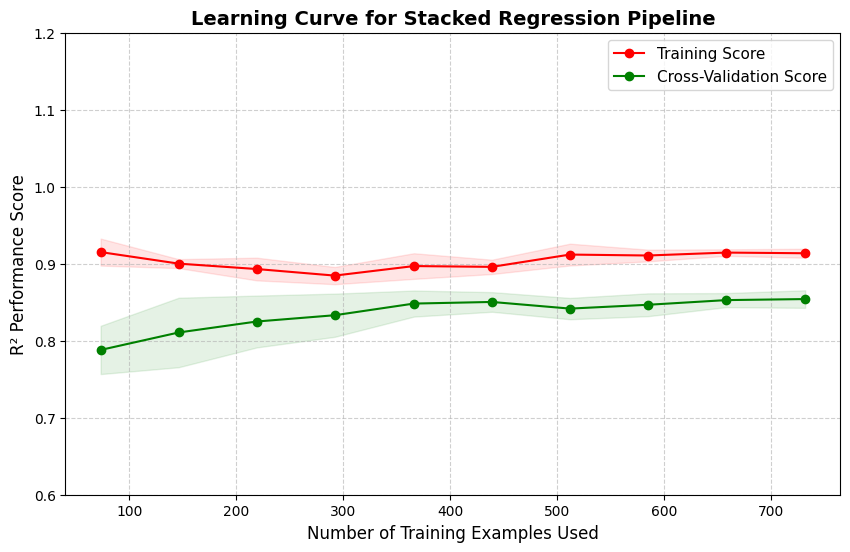

In [ ]:
import numpy as np
import matplotlib.pyplot as plt




# 2. Calculate the learning curve data
# train_sizes dictates the fractions of the training set to use (e.g., 10% up to 100%)
gpr_train_sizes, gpr_train_scores, gpr_validation_scores = learning_curve(
    estimator=pipeline,
    X=x_train,
    y=y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,                  # 5-fold cross-validation at each data size step
    scoring='r2',          # Evaluate using the R² score
    n_jobs=-1
)

# 3. Calculate the mean and standard deviation across the CV folds
gpr_train_mean = np.mean(gpr_train_scores, axis=1)
gpr_train_std = np.std(gpr_train_scores, axis=1)
gpr_validation_mean = np.mean(gpr_validation_scores, axis=1)
gpr_validation_std = np.std(gpr_validation_scores, axis=1)

# 4. Generate the plot
plt.figure(figsize=(10, 6))

# Plot training scores
plt.plot(gpr_train_sizes, gpr_train_mean, 'o-', color="r", label="Training Score")
plt.fill_between(gpr_train_sizes, gpr_train_mean - gpr_train_std, gpr_train_mean + gpr_train_std, alpha=0.1, color="r")

# Plot validation scores
plt.plot(gpr_train_sizes, gpr_validation_mean, 'o-', color="g", label="Cross-Validation Score")
plt.fill_between(gpr_train_sizes, gpr_validation_mean - gpr_validation_std, gpr_validation_mean + gpr_validation_std, alpha=0.1, color="g")

# Formatting elements
plt.title("Learning Curve for Stacked Regression Pipeline", fontsize=14, fontweight='bold')

plt.xlabel("Number of Training Examples Used", fontsize=12)
plt.ylabel("R² Performance Score", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc="best", fontsize=11)
plt.ylim(0.6, 1.2) # Caps the Y-axis logically for R² interpretation
plt.show()

KNN GPR BR Ensemble

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import StackingRegressor
from sklearn.model_selection import GridSearchCV

#kernel = 1*RBF(length_scale=[1.0,1.0,1.0,1.0], length_scale_bounds=(1e-2, 1e2))

base_learners = [
    ('gpr', GaussianProcessRegressor(optimizer=None, normalize_y=True,  alpha=1e-3)),
    ('knn', KNeighborsRegressor())
]

stacking_ensemble = StackingRegressor(
    estimators=base_learners,
    final_estimator=RidgeCV(),
    cv = 3

)

pipeline = Pipeline([
  ('scaler', StandardScaler()),
  ('stack', stacking_ensemble)
])

param_grid = {

    "stack__gpr__kernel": [
        1.0 * RBF(length_scale=[0.5, 0.5, 0.5, 0.5], length_scale_bounds="fixed"),
        1.0 * RBF(length_scale=[1.0, 1.0, 1.0, 1.0], length_scale_bounds="fixed"),
        1.0 * RBF(length_scale=[2.0, 2.0, 2.0, 2.0], length_scale_bounds="fixed"),
        # You can add specific custom weighting if you suspect a feature is highly sensitive:
        1.0 * RBF(length_scale=[0.5, 2.0, 1.0, 1.0], length_scale_bounds="fixed"),
    ],
    # Tune the KNN model hidden inside the stack step
    'stack__gpr__alpha': [1e-4, 1e-2, 1e0],

    # Tune the weights parameter of the KNN model inside the stack step
    'stack__knn__weights': ['uniform'],
    'stack__knn__n_neighbors': [9,11,15,21]


}
grid_gpr = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
)

grid_gpr.fit(x_train, y_train)

try:
    print("Training grid search sequentially... please wait...")
    grid_gpr.fit(x_train, y_train)

    print("\n--- Model Trained Successfully! ---")
    print(f"Best Parameters: {grid_gpr.best_params_}")
    print(f"Best CV R² Score: {grid_gpr.best_score_:.4f}")
    print(f"Test Set R² Score: {grid_gpr.score(x_test, y_test):.4f}")

except Exception as e:
    print("\n--- Execution Failed! Concrete Error Details Below: ---")
    print(repr(e))

Training grid search sequentially... please wait...

--- Model Trained Successfully! ---
Best Parameters: {'stack__gpr__alpha': 0.01, 'stack__gpr__kernel': 1**2 * RBF(length_scale=[1, 1, 1, 1]), 'stack__knn__n_neighbors': 15, 'stack__knn__weights': 'uniform'}
Best CV R² Score: 0.8601
Test Set R² Score: 0.8509


In [ ]:
gpr_train_score = grid_gpr.score(x_train, y_train)

# 2. Calculate the score on the test data
gpr_test_score = grid_gpr.score(x_test, y_test)

print(f"Training R² Score: {gpr_train_score:.4f}")
print(f"Test R² Score:     {gpr_test_score:.4f}")

# 3. Evaluate the gap
gap = gpr_train_score - gpr_test_score
print(f"Performance Gap:   {gap:.4f}")

Training R² Score: 0.9208
Test R² Score:     0.8509
Performance Gap:   0.0699


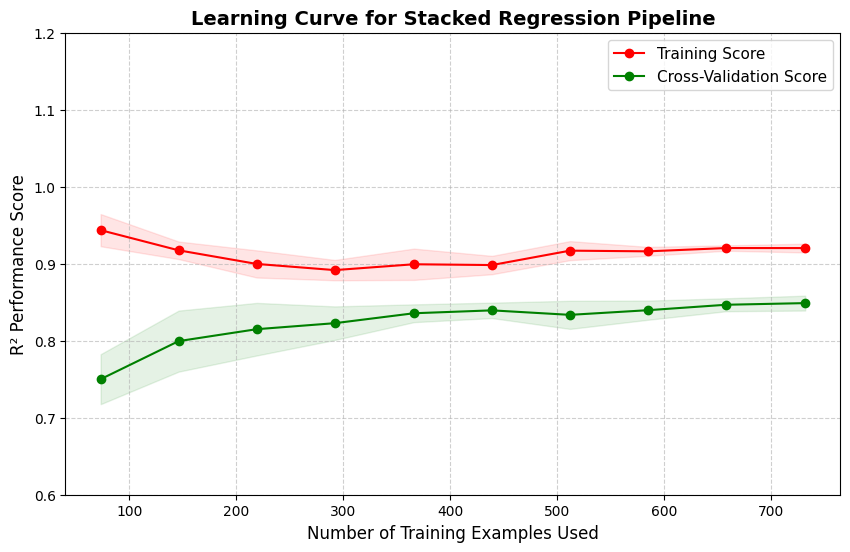

In [ ]:
import numpy as np
import matplotlib.pyplot as plt




# 2. Calculate the learning curve data
# train_sizes dictates the fractions of the training set to use (e.g., 10% up to 100%)
gpr_train_sizes, gpr_train_scores, gpr_validation_scores = learning_curve(
    estimator=pipeline,
    X=x_train,
    y=y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,                  # 5-fold cross-validation at each data size step
    scoring='r2',          # Evaluate using the R² score
    n_jobs=-1
)

# 3. Calculate the mean and standard deviation across the CV folds
gpr_train_mean = np.mean(gpr_train_scores, axis=1)
gpr_train_std = np.std(gpr_train_scores, axis=1)
gpr_validation_mean = np.mean(gpr_validation_scores, axis=1)
gpr_validation_std = np.std(gpr_validation_scores, axis=1)

# 4. Generate the plot
plt.figure(figsize=(10, 6))

# Plot training scores
plt.plot(gpr_train_sizes, gpr_train_mean, 'o-', color="r", label="Training Score")
plt.fill_between(gpr_train_sizes, gpr_train_mean - gpr_train_std, gpr_train_mean + gpr_train_std, alpha=0.1, color="r")

# Plot validation scores
plt.plot(gpr_train_sizes, gpr_validation_mean, 'o-', color="g", label="Cross-Validation Score")
plt.fill_between(gpr_train_sizes, gpr_validation_mean - gpr_validation_std, gpr_validation_mean + gpr_validation_std, alpha=0.1, color="g")

# Formatting elements
plt.title("Learning Curve for Stacked Regression Pipeline", fontsize=14, fontweight='bold')

plt.xlabel("Number of Training Examples Used", fontsize=12)
plt.ylabel("R² Performance Score", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc="best", fontsize=11)
plt.ylim(0.6, 1.2) # Caps the Y-axis logically for R² interpretation
plt.show()

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import StackingRegressor
from sklearn.model_selection import GridSearchCV

#kernel = 1*RBF(length_scale=[1.0,1.0,1.0,1.0], length_scale_bounds=(1e-2, 1e2))

base_learners = [
    ('gpr', GaussianProcessRegressor(optimizer=None, normalize_y=True,  alpha=1e-3)),
    ('knn', KNeighborsRegressor())
]

stacking_ensemble = StackingRegressor(
    estimators=base_learners,
    final_estimator=RidgeCV(),
    cv = 3

)

pipeline = Pipeline([
  ('scaler', StandardScaler()),
  ('stack', stacking_ensemble)
])

param_grid = {

    "stack__gpr__kernel": [
        1.0 * RBF(length_scale=[0.5, 0.5, 0.5, 0.5], length_scale_bounds="fixed"),
        1.0 * RBF(length_scale=[1.0, 1.0, 1.0, 1.0], length_scale_bounds="fixed"),
        1.0 * RBF(length_scale=[2.0, 2.0, 2.0, 2.0], length_scale_bounds="fixed"),
        # You can add specific custom weighting if you suspect a feature is highly sensitive:
        1.0 * RBF(length_scale=[0.5, 2.0, 1.0, 1.0], length_scale_bounds="fixed"),
    ],
    # Tune the KNN model hidden inside the stack step
    'stack__gpr__alpha': [1e-4, 1e-2, 1e0],

    # Tune the weights parameter of the KNN model inside the stack step
    'stack__knn__weights': ['uniform'],
    'stack__knn__n_neighbors': [9,11,15,21]


}
grid_gpr = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
)

grid_gpr.fit(x_train, y_train)

try:
    print("Training grid search sequentially... please wait...")
    grid_gpr.fit(x_train, y_train)

    print("\n--- Model Trained Successfully! ---")
    print(f"Best Parameters: {grid_gpr.best_params_}")
    print(f"Best CV R² Score: {grid_gpr.best_score_:.4f}")
    print(f"Test Set R² Score: {grid_gpr.score(x_test, y_test):.4f}")

except Exception as e:
    print("\n--- Execution Failed! Concrete Error Details Below: ---")
    print(repr(e))

Training grid search sequentially... please wait...

--- Model Trained Successfully! ---
Best Parameters: {'stack__gpr__alpha': 0.01, 'stack__gpr__kernel': 1**2 * RBF(length_scale=[1, 1, 1, 1]), 'stack__knn__n_neighbors': 15, 'stack__knn__weights': 'uniform'}
Best CV R² Score: 0.8601
Test Set R² Score: 0.8509


#test for benzoic acid